---
# **ML4BI2 Exam - Part 2**
---
**Goal**

Dataset contains pictures and labels for 25 different grocery categories. The main goal is to train a CNN model to classify image labels based on the picture.

The problem is multi-class single-label prediction (one of 25 labels)

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
import os, zipfile, time

# --- Paths --------------------------------------------------------------------
DRIVE_DIR     = '/content/gdrive/MyDrive/ML2'
MODEL_DIR     = DRIVE_DIR
EXTRACT_DIR   = '/content/data'

# --- Test data -------------------------------------------------
ZIP_PATH      = '/content/gdrive/MyDrive/ML2/exam_ML4BI2_2026_Freiburg_test.zip'
TEST_DIR      = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'test')

# --- Unzipping data -------------------------------------------------
if not os.path.exists(TEST_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print(f'Extracted to {EXTRACT_DIR}')
else:
    print('Already extracted to local SSD.')

# --- Saved model paths --------------------------------------------------------
FROM_SCRATCH_PATH = os.path.join(MODEL_DIR, 'best_from_scratch_Freiburg.keras')
PRETRAINED_PATH   = os.path.join(MODEL_DIR, 'best_finetuned_Freiburg.keras')

print('MODEL_DIR        :', MODEL_DIR)
print('TEST_DIR         :', TEST_DIR)
print('From-scratch model:', FROM_SCRATCH_PATH, '— exists:', os.path.exists(FROM_SCRATCH_PATH))
print('Pretrained model:', PRETRAINED_PATH,   '— exists:', os.path.exists(PRETRAINED_PATH))

Extracted to /content/data
MODEL_DIR        : /content/gdrive/MyDrive/ML2
TEST_DIR         : /content/data/exam_ML4BI2_2026/test
From-scratch model: /content/gdrive/MyDrive/ML2/best_from_scratch_Freiburg.keras — exists: True
Pretrained model: /content/gdrive/MyDrive/ML2/best_finetuned_Freiburg.keras — exists: True


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print('TF version:', tf.__version__)

# Reproducibility
keras.utils.set_random_seed(42)

TF version: 2.20.0


In [4]:
IMG_SIZE   = (224, 224)
BATCH_SIZE = 64

# shuffle=False keeps the per-image order deterministic — important later
# because the Grad-CAM section maps a prediction index back to a file path
# (alphabetical class folder → alphabetical filename within).
test_dataset = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False,
)

# Class names taken from the test folder
class_names = test_dataset.class_names
num_classes = len(class_names)
print(f'\nClasses ({num_classes}):', class_names)

# Performance: prefetch overlaps I/O with GPU compute
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

# Quick sanity check
for x, y in test_dataset.take(1):
    print(f'\nBatch shape: {x.shape}, label shape: {y.shape}')
    print(f'Pixel range: {float(tf.reduce_min(x)):.1f} → {float(tf.reduce_max(x)):.1f}')

Found 495 files belonging to 25 classes.

Classes (25): ['beans', 'cake', 'candy', 'cereal', 'chips', 'chocolate', 'coffee', 'corn', 'fish', 'flour', 'honey', 'jam', 'juice', 'milk', 'nuts', 'oil', 'pasta', 'rice', 'soda', 'spices', 'sugar', 'tea', 'tomato_sauce', 'vinegar', 'water']

Batch shape: (64, 224, 224, 3), label shape: (64, 25)
Pixel range: 0.0 → 255.0


Comparing shape, pixel range, and class labels, it matches train/val setting.

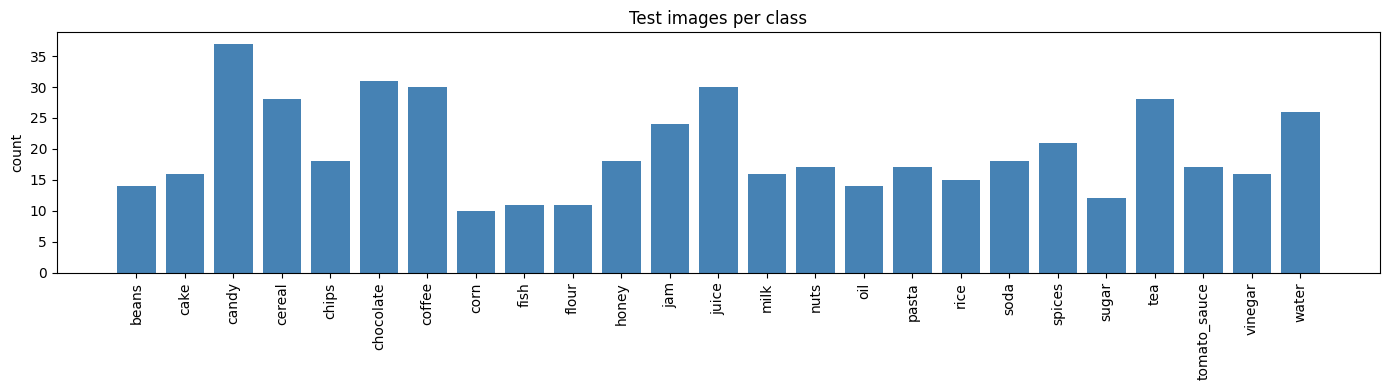

Total test images : 495
Per class         : mean 19.8, min 10, max 37


In [5]:
# --- Per-class image counts in the test set --------------------------------
test_counts = {c: len(os.listdir(os.path.join(TEST_DIR, c))) for c in class_names}

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(test_counts.keys(), test_counts.values(), color='steelblue')
ax.set_title('Test images per class')
ax.tick_params(axis='x', rotation=90)
ax.set_ylabel('count')
plt.tight_layout(); plt.show()

total_test = sum(test_counts.values())
print(f'Total test images : {total_test}')
print(f'Per class         : mean {np.mean(list(test_counts.values())):.1f}, '
      f'min {min(test_counts.values())}, max {max(test_counts.values())}')

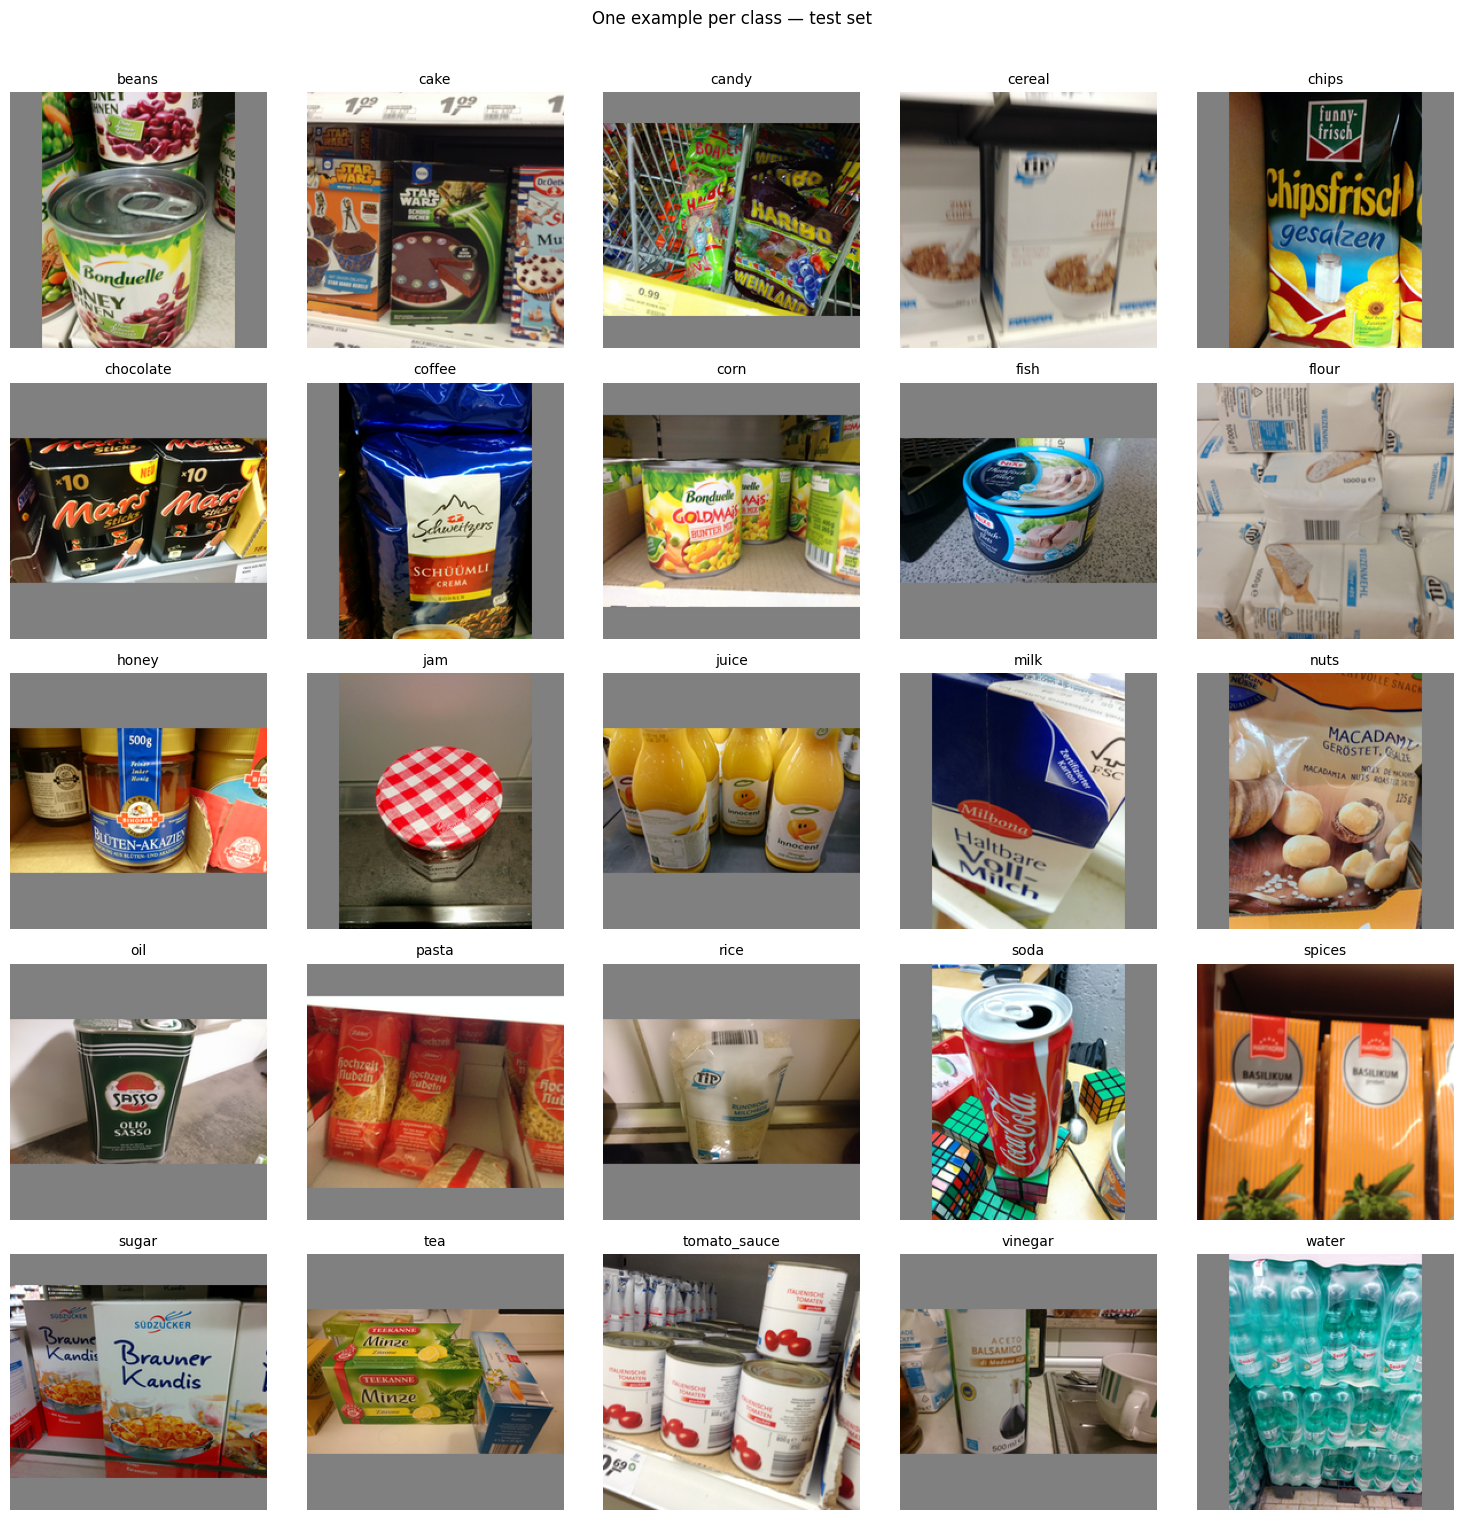

In [6]:
# --- Visual check: one picture per class -------------------------
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for ax, cls in zip(axes.ravel(), class_names):
    fname = sorted(os.listdir(os.path.join(TEST_DIR, cls)))[0]
    img = keras.utils.load_img(os.path.join(TEST_DIR, cls, fname))
    ax.imshow(img); ax.set_title(cls, fontsize=10); ax.axis('off')
plt.suptitle('One example per class — test set', y=1.01)
plt.tight_layout(); plt.show()

---
##**QUESTION 1.1**

In [7]:
# Load both saved models from Drive — no retraining here.
print(f'Loading from-scratch model from: {FROM_SCRATCH_PATH}')
model_scratch = keras.models.load_model(FROM_SCRATCH_PATH)

print(f'Loading pretrained model from : {PRETRAINED_PATH}')
model_pretrained = keras.models.load_model(PRETRAINED_PATH)

print('\nBoth models loaded successfully.')
print(f'  from-scratch   — {model_scratch.count_params():,} params')
print(f'  pretrained     — {model_pretrained.count_params():,} params')

Loading from-scratch model from: /content/gdrive/MyDrive/ML2/best_from_scratch_Freiburg.keras
Loading pretrained model from : /content/gdrive/MyDrive/ML2/best_finetuned_Freiburg.keras

Both models loaded successfully.
  from-scratch   — 4,901,113 params
  pretrained     — 5,951,337 params


In [8]:
def eval_model(model, dataset, name):
    """Run model.evaluate and return a clean dict of metrics."""
    metrics = model.evaluate(dataset, verbose=0)
    row = {'model': name}
    for k, v in zip(model.metrics_names, metrics):
        row[k] = float(v)
    return row

rows = [
    eval_model(model_scratch,    test_dataset, 'From-scratch'),
    eval_model(model_pretrained, test_dataset, 'Pretrained'),
]
results_df = pd.DataFrame(rows).set_index('model')
print('Test-set metrics:\n')
print(results_df.to_string(float_format='%.4f'))

Test-set metrics:

               loss  compile_metrics
model                               
From-scratch 1.7154           0.6465
Pretrained   0.6073           0.8222


Results between from-scratch and pretrained models were expected. I slightly overfitted to train/val modelling part so it does not perform good enough. But on that small dataset it's still pretty good result. I expected accuracy around 50%.

The pretrained model is way better since the training set is way bigger. This is not surprising and expected.

Collected 495 test predictions for from-scratch model.
Test accuracy: 0.6465


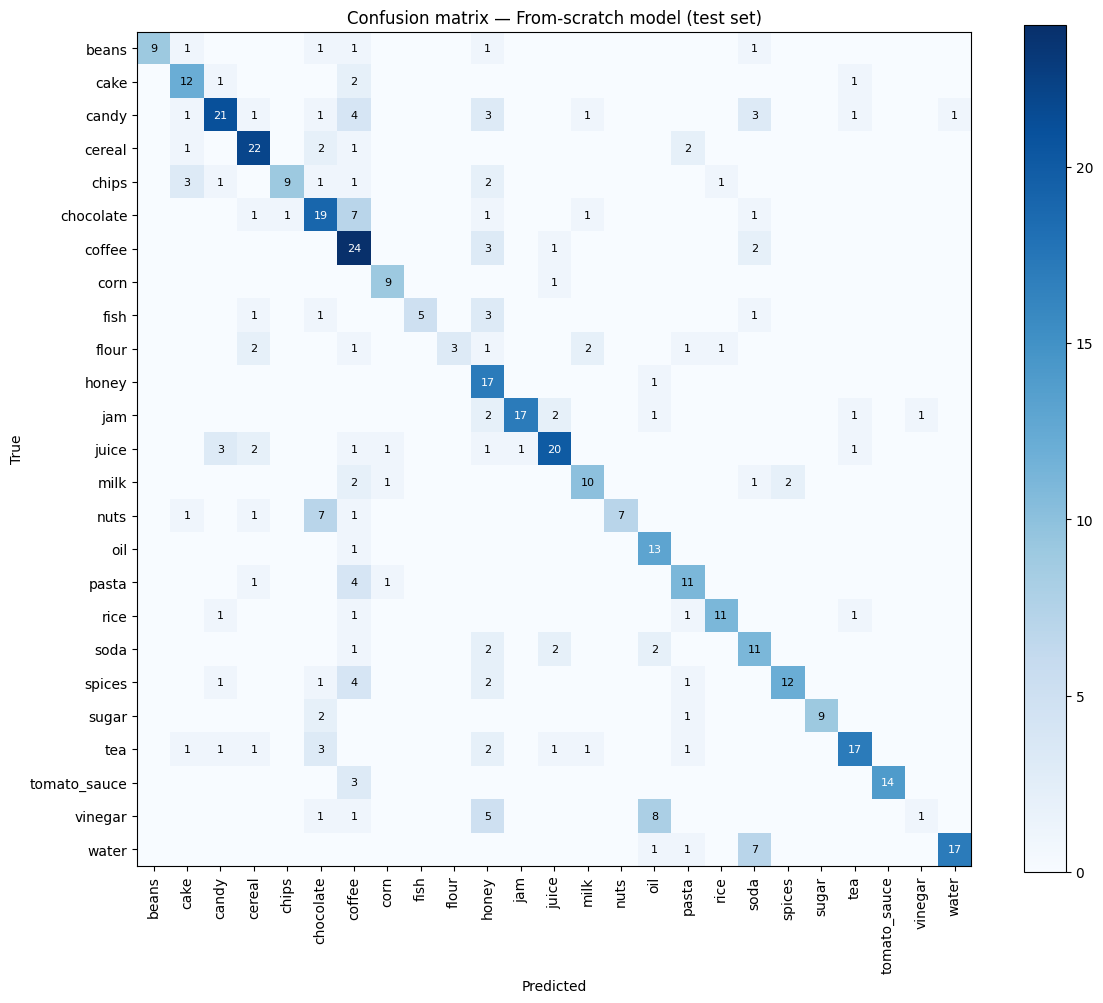

In [9]:
# Collect predictions for the from-scratch model.
def collect_predictions(model, dataset):
    y_true_list, y_prob_list = [], []
    for x, y in dataset:
        y_prob_list.append(model.predict(x, verbose=0))
        y_true_list.append(y.numpy())
    y_prob = np.concatenate(y_prob_list)
    y_true = np.concatenate(y_true_list)
    y_pred = np.argmax(y_prob, axis=1)
    y_true_idx = np.argmax(y_true, axis=1)
    return y_true_idx, y_pred, y_prob

y_true_s, y_pred_s, y_prob_s = collect_predictions(model_scratch, test_dataset)
print(f'Collected {len(y_true_s)} test predictions for from-scratch model.')
print(f'Test accuracy: {(y_pred_s == y_true_s).mean():.4f}')

# Confusion matrix — from-scratch
cm_s = confusion_matrix(y_true_s, y_pred_s)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_s, cmap='Blues')
ax.set_xticks(range(num_classes)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(num_classes)); ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion matrix — From-scratch model (test set)')
# Annotate cells with counts (only non-zero, to keep it readable)
for i in range(num_classes):
    for j in range(num_classes):
        if cm_s[i, j] > 0:
            ax.text(j, i, cm_s[i, j], ha='center', va='center',
                    color='white' if cm_s[i, j] > cm_s.max()/2 else 'black', fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

**Conclusion:**

- **Well classified categories:** coffee, candy, cereal and juice.
In these well-classified categories, the biggest advantage is  representativness in training. These categories included the most of train pictures so for model it is easier to classify these variables than the other.
- **Badly classified categories:** vinegar, flour, fish and nuts.
For vinegar it is obvious "structure and texture" confusion. Most of pictures with vinegar were identified as oil or honey. It makes sense because of similar color, texture, bottles. Similar case with flour when it was classified as milk or cereals (again similarity in color, lack of predictive power on the detailed structure/texture)

Training set was imbalanced and now I can see the result. Model is guessing mostly coffe, candy, cereal, juice which is easiest for the model since the representativness was the highest (easy to classify when I keep trying returning most common categories)
Model lacks enough predictive power on details such texture/structure. I would assume, this is pretty logical for the model built from scratch which was trained only on ~4000 images. To catch the structure and details, way more observations are needed (that's the main reason of fine-tuning pretrained models)

---
##**QUESTION 1.2**

In [10]:
import matplotlib.cm as cm
from PIL import Image

# --- 1. Build the file-path list in the SAME order as test_dataset ---------
valid_exts = ('.bmp', '.gif', '.jpeg', '.jpg', '.png')
test_file_paths = []
for cls in class_names:
    cls_dir = os.path.join(TEST_DIR, cls)
    for f in sorted(os.listdir(cls_dir)):
        if f.lower().endswith(valid_exts):
            test_file_paths.append(os.path.join(cls_dir, f))

assert len(test_file_paths) == len(y_true_s), (
    f'File-path count ({len(test_file_paths)}) does not match prediction count ({len(y_true_s)}). '
    f'Did test_dataset use shuffle=True somewhere?'
)
print(f'Built {len(test_file_paths)} (index -> file path) mappings.')


# --- 2. Helper that runs Grad-CAM for one model and shows top-5 ------------
def gradcam_top5(model, y_true, y_pred, y_prob, model_name, conv_base_name=None):
    # --- 2a. Per-sample categorical cross-entropy and top-5 by loss -------
    eps = 1e-7
    losses = -np.log(y_prob[np.arange(len(y_true)), y_true] + eps)
    top5   = np.argsort(losses)[::-1][:5]

    # --- 2b. Build a grad_model that returns (last_conv_feature_map, pred)
    if conv_base_name is None:
        # Conv layer is at the top level of `model` (from-scratch case).
        last_conv_name = next(
            l.name for l in reversed(model.layers)
            if hasattr(l, 'output') and len(l.output.shape) == 4
        )
        grad_model = keras.Model(
            model.inputs,
            [model.get_layer(last_conv_name).output, model.output],
        )
    else:
        # Conv layer is nested inside `conv_base_name` (EfficientNet case).
        conv_base = model.get_layer(conv_base_name)
        last_conv_name = next(
            l.name for l in reversed(conv_base.layers)
            if hasattr(l, 'output') and len(l.output.shape) == 4
        )
        # Extended base that returns both the chosen feature map AND the
        # base's final output — exactly the trick from the in-class
        # gradcam_top5_loss_notebook.
        base_ext = keras.Model(
            conv_base.input,
            [conv_base.get_layer(last_conv_name).output, conv_base.output],
            name=conv_base_name + '_ext',
        )
        # Re-thread the forward pass of the top-level model, swapping
        # the original base for base_ext. Layers are reused (same weights).
        inp = keras.Input(shape=IMG_SIZE + (3,))
        x, conv_features = inp, None
        for layer in model.layers:
            if isinstance(layer, keras.layers.InputLayer):
                continue
            elif layer.name == conv_base_name:
                conv_features, x = base_ext(x)
            else:
                x = layer(x)
        grad_model = keras.Model(inp, [conv_features, x])

    print(f'{model_name}: using last conv layer = "{last_conv_name}"')

    # --- 2c. Plot 5 rows × 3 columns: original | heatmap | overlay ---------
    fig, axes = plt.subplots(5, 3, figsize=(12, 18))
    for row, idx in enumerate(top5):
        img_path = test_file_paths[idx]
        img_pil  = keras.utils.load_img(img_path, target_size=IMG_SIZE)
        img_arr  = np.expand_dims(keras.utils.img_to_array(img_pil), axis=0)

        # ---- Grad-CAM ---------------------------------------------------
        img_tensor = tf.constant(img_arr, dtype='float32')
        with tf.GradientTape() as tape:
            conv_out, preds = grad_model(img_tensor, training=False)
            pred_idx = int(y_pred[idx])
            class_score = preds[:, pred_idx]
        grads      = tape.gradient(class_score, conv_out)
        pooled     = tf.reduce_mean(grads, axis=(0, 1, 2))
        heatmap    = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
        heatmap    = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
        heatmap_np = heatmap.numpy()

        # ---- Overlay ----------------------------------------------------
        original   = keras.utils.img_to_array(img_pil).astype('uint8')
        hm_uint8   = np.uint8(255 * heatmap_np)
        jet_colors = cm.get_cmap('jet')(np.arange(256))[:, :3]
        jet_hm     = np.uint8(jet_colors[hm_uint8] * 255)
        jet_hm     = np.array(Image.fromarray(jet_hm).resize(
            (original.shape[1], original.shape[0])
        ))
        overlay    = np.uint8(jet_hm * 0.4 + original * 0.6)

        # ---- Plot -------------------------------------------------------
        true_cls = class_names[int(y_true[idx])]
        pred_cls = class_names[pred_idx]
        conf     = y_prob[idx, pred_idx]
        axes[row, 0].imshow(original)
        axes[row, 0].set_title(
            f'True: {true_cls}\nPred: {pred_cls} ({conf:.2f})\nLoss: {losses[idx]:.2f}',
            fontsize=9,
        )
        axes[row, 0].axis('off')
        axes[row, 1].imshow(heatmap_np, cmap='jet')
        axes[row, 1].set_title('Grad-CAM heatmap', fontsize=9)
        axes[row, 1].axis('off')
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title('Overlay', fontsize=9)
        axes[row, 2].axis('off')

    fig.suptitle(
        f'{model_name} — top-5 highest-loss test predictions (Grad-CAM)',
        fontsize=12, y=1.005,
    )
    plt.tight_layout(); plt.show()


Built 495 (index -> file path) mappings.


FROM-SCRATCH: using last conv layer = "activation_89"


/tmp/ipykernel_892/2258246094.py:90: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet_colors = cm.get_cmap('jet')(np.arange(256))[:, :3]


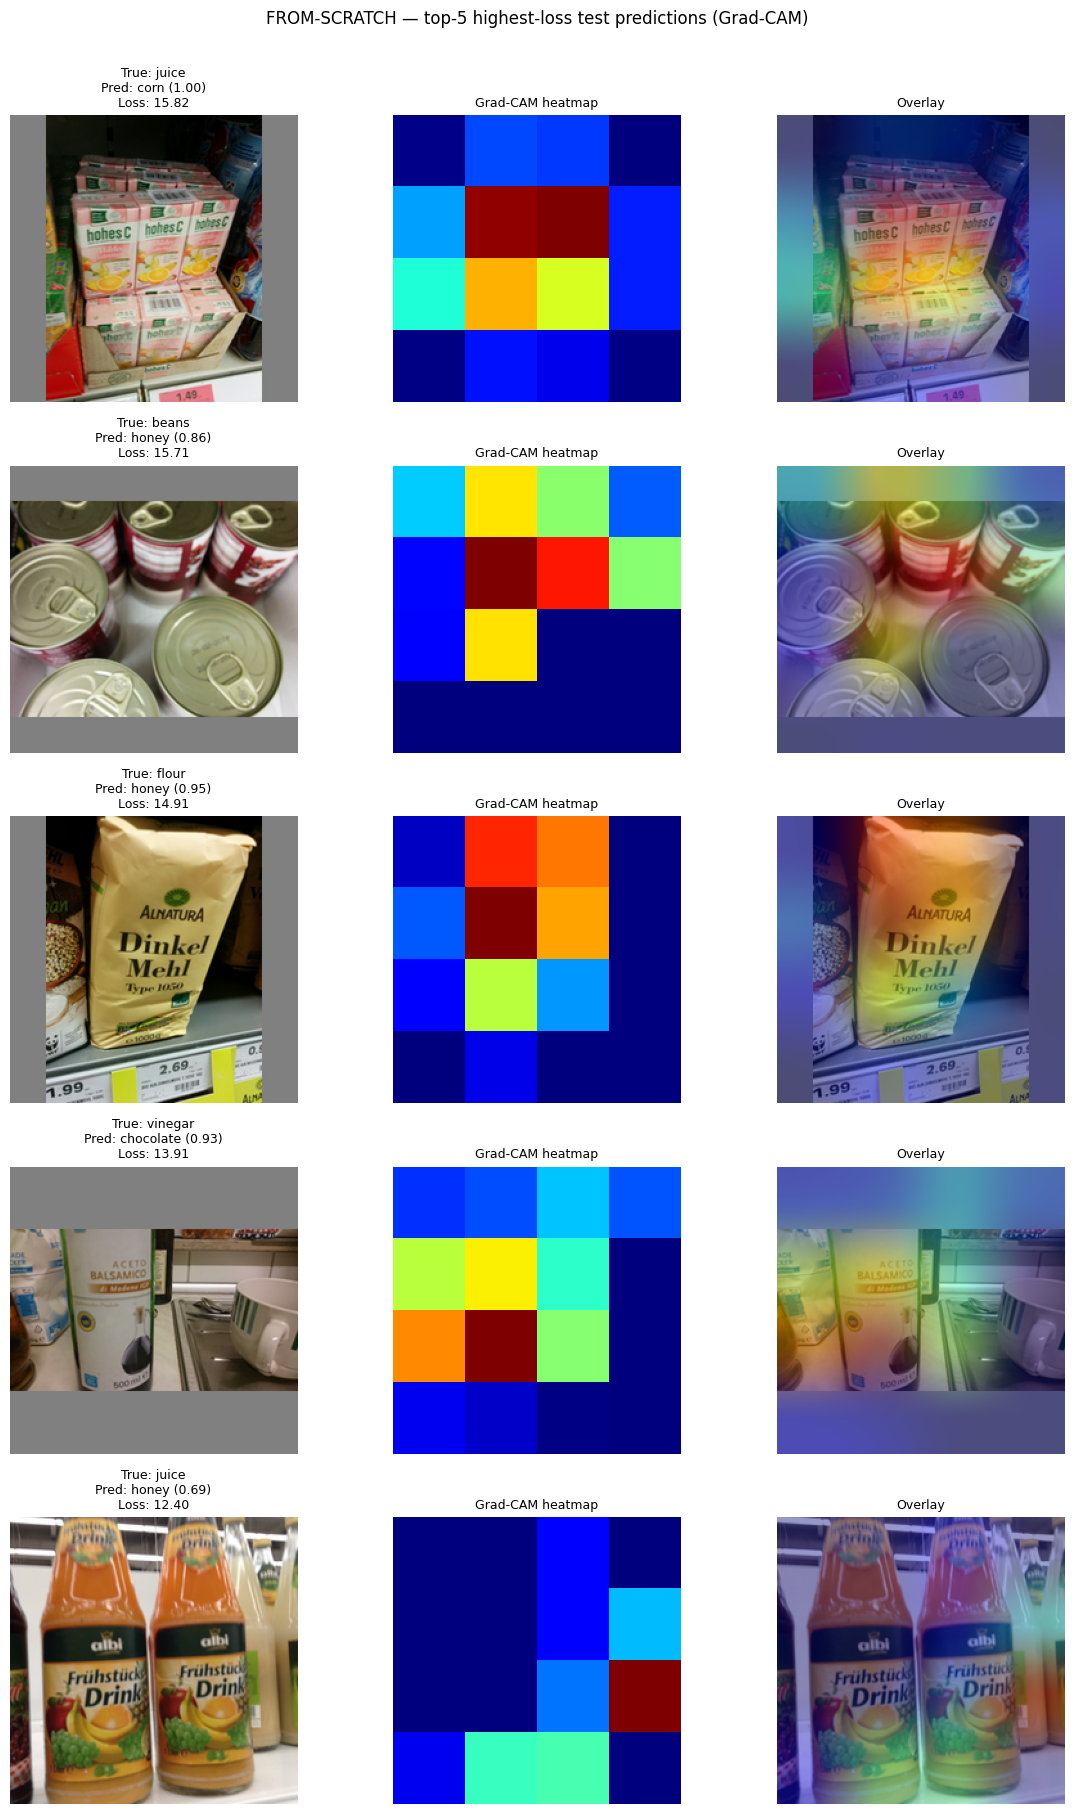

In [11]:
# --- Grad-CAM on from-scratch model ---------------------------------------
# All conv layers are at the top level, so conv_base_name=None.
gradcam_top5(
    model=model_scratch,
    y_true=y_true_s, y_pred=y_pred_s, y_prob=y_prob_s,
    model_name='FROM-SCRATCH',
    conv_base_name=None,
)

**Conclusion:**

The model looks correctly on main objects. As I mentioned earlier, it is really obvious from these 5 samples that model struggles to get details about structure and texture.

1. Picture: It "looks" correctly at the packaging, however it identified a yellow color and juice had unusual packaging so it underperforms and classified the object as corn instead juice
2. Picture: Model evaluated a category based on the top of cans and noise arround, since the color of top is similar to color of honey, it was missclassified again.
3. Picture: similar to 3. picture. Packaging for flour was similar color than to color of honey.
4. Picture: classified as chocolate due to contract white and brown on the bottle. Completely miss-classified due to texture detail.
5. Picture: Model classified it based on the bottom part of the package label, color is again similar to honey.

I can confirm my earlier assumption that model struggles really badly on texture and structure details. That's what I kind of expected because the training a validation set was pretty small to detect these details.


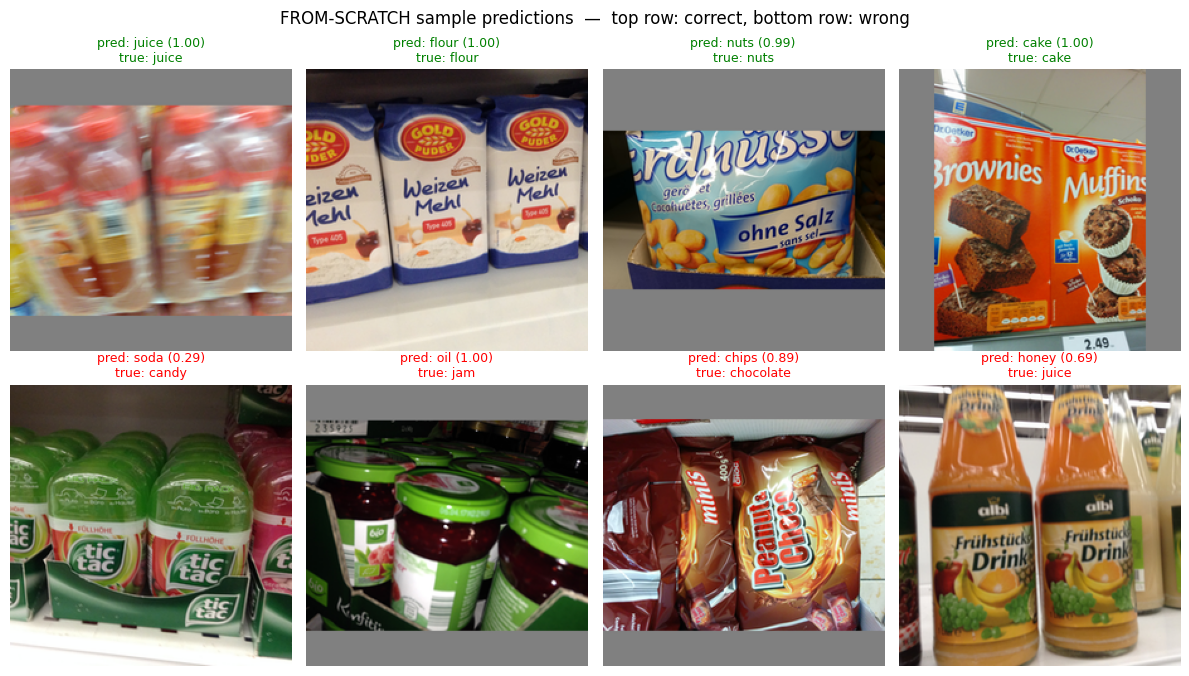

In [12]:
# Sample predictions — 4 correct + 4 wrong, with predicted class and confidence
def gather_sample_images(dataset, n=20):
    """Return up to n (image, true_idx) tuples in order they appear in the dataset."""
    imgs, labels = [], []
    for x, y in dataset:
        for i in range(x.shape[0]):
            imgs.append(x[i].numpy().astype('uint8'))
            labels.append(int(np.argmax(y[i].numpy())))
            if len(imgs) >= n:
                return imgs, labels
    return imgs, labels

def plot_predictions(model, y_true, y_pred, y_prob, n_correct=4, n_wrong=4, title=''):
    correct_idx = np.where(y_true == y_pred)[0]
    wrong_idx   = np.where(y_true != y_pred)[0]
    pick_correct = np.random.choice(correct_idx, size=min(n_correct, len(correct_idx)), replace=False)
    pick_wrong   = np.random.choice(wrong_idx,   size=min(n_wrong,   len(wrong_idx)),   replace=False)
    picks = list(pick_correct) + list(pick_wrong)

    # Pull just the images we need (avoid loading the whole dataset into RAM)
    needed = set(picks); imgs = {}
    counter = 0
    for x, _ in test_dataset:
        for i in range(x.shape[0]):
            if counter in needed:
                imgs[counter] = x[i].numpy().astype('uint8')
            counter += 1
        if len(imgs) == len(needed):
            break

    cols = max(n_correct, n_wrong)
    fig, axes = plt.subplots(2, cols, figsize=(3*cols, 7))
    for row, group in enumerate([pick_correct, pick_wrong]):
        for col in range(cols):
            ax = axes[row, col]
            if col < len(group):
                idx = group[col]
                ax.imshow(imgs[idx])
                pred_cls = class_names[y_pred[idx]]
                true_cls = class_names[y_true[idx]]
                conf = y_prob[idx, y_pred[idx]]
                color = 'green' if y_true[idx] == y_pred[idx] else 'red'
                ax.set_title(f'pred: {pred_cls} ({conf:.2f})\ntrue: {true_cls}',
                             fontsize=9, color=color)
            ax.axis('off')
    fig.suptitle(f'{title}  —  top row: correct, bottom row: wrong', fontsize=12)
    plt.tight_layout(); plt.show()

plot_predictions(model_scratch, y_true_s, y_pred_s, y_prob_s,
                 title='FROM-SCRATCH sample predictions')

---
##**QUESTION 1.3**

In [13]:
TRAIN_DIR = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'train')
VAL_DIR   = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'validation')

In [14]:
# Load training data
train_dataset = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
)

val_dataset = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False,
)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)

Found 3957 files belonging to 25 classes.
Found 495 files belonging to 25 classes.


In [18]:
# Best practices selected:
# 1. Data augmentation     - dataset is small (~4000 images, 25 classes)
#                            augmentation artificially expands training variety
#                            and prevents overfitting to exact image orientations
# 2. Increasing filters    - 64->128->256->512 follows textbook recommendation;
#                            early layers detect edges/textures, deeper layers
#                            detect class-specific patterns (packaging, colour)
# 4. Dropout               - regularisation against overfitting; critical here
#                            because 25 classes with ~200 images each is limited
# 5. EarlyStopping         - stops training when val_loss stops improving,
#                            preventing overfitting without manual epoch tuning
# 6. ReduceLROnPlateau     - fine-tunes learning rate when training plateaus,
#                            helping escape local minima in later epochs
# 7. GlobalAveragePooling  - helps better for multi-class classification, Flatten() would cause bad results


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="data_augmentation")

# 4-layer CNN following textbook best practices
# Each layer = Conv2D -> MaxPool
model_new_scratch = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),

    # Rescale pixel values [0,255] -> [0,1]
    # Required for stable gradient flow; raw pixel values cause
    # exploding gradients in early training
    layers.Rescaling(1./255),

    # Data augmentation applied only during training (Keras handles this automatically)
    data_augmentation,

    # 4 basic layers
    layers.Conv2D(filters=64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(filters=128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(filters=256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(filters=512, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),


    # ── Classification head ───────────────────────────────────────
    layers.GlobalAveragePooling2D(),
    # Dense layer combines spatial features into class predictions
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),  # stronger dropout before output — most critical point
                           # for preventing overfitting with 25 classes
    layers.Dense(num_classes, activation='softmax')  # softmax for multiclass
], name="new_from_scratch_cnn")

model_new_scratch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',  # correct loss for one-hot encoded 25-class problem
    metrics=['accuracy'],
)

model_new_scratch.summary()

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True  # restores weights from best epoch, not last
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=7,
        min_lr=1e-5
    ),
]

history = model_new_scratch.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=callbacks
)

Model: "new_from_scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 222, 222, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 109, 109, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 52, 52, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 26, 26, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,619,865 (6.18 MB)

 Trainable params: 1,619,865 (6.18 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 22s 278ms/step - accuracy: 0.0665 - loss: 3.1832 - val_accuracy: 0.0788 - val_loss: 3.1103 - learning_rate: 0.0010
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 239ms/step - accuracy: 0.1046 - loss: 3.0684 - val_accuracy: 0.1515 - val_loss: 2.9591 - learning_rate: 0.0010
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 234ms/step - accuracy: 0.1372 - loss: 2.9584 - val_accuracy: 0.1596 - val_loss: 2.9273 - learning_rate: 0.0010
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 225ms/step - accuracy: 0.1569 - loss: 2.8903 - val_accuracy: 0.1697 - val_loss: 2.8241 - learning_rate: 0.0010
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 223ms/step - accuracy: 0.1562 - loss: 2.8511 - val_accuracy: 0.1838 - val_loss: 2.7911 - learning_rate: 0.0010
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 224ms/step - accuracy: 0.1638 - loss: 2.8318 - val_accuracy: 0.1899 - val_loss: 2.7341 - learning_rate: 0.0010
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 227ms/step - accuracy: 0.1739 - l

I am not really sure I understand this question properly. I chose 4 basic layers only without residual blocks or any additive methods due to time required for training.

The best practice for this dataset is data augmentation for sure, following by BatchNorm and residual blocks. All three combined helps fighting the overfitting which can occur with this dataset.

1. Data augmentation     - dataset is small (~4000 images, 25 classes) augmentation artificially expands training variety and prevents overfitting to exact image orientations
2. Increasing filters    - 64->128->256->512 follows textbook recommendation. early layers detect edges/textures, deeper layers detect class-specific patterns (packaging, colour)
3. Dropout               - regularisation against overfitting; critical here because 25 classes with ~200 images each is limited
4. EarlyStopping         - stops training when val_loss stops improving, preventing overfitting without manual epoch tuning
5. ReduceLROnPlateau     - fine-tunes learning rate when training plateaus,
helping escape local minima in later epochs
6. GlobalAveragePooling  - helps better for multi-class classification, Flatten() would cause bad results

On my model from scratch I used residual blocks of conv2d (32,64,128,256)
 Within one block:


*  First Conv -> BN -> ReLU
*  Second Conv -> BN -> MaxPool (Downsample happens here)
*  1x1 Conv with stride=2 matches the downsampling of the MaxPool layer
* Add -> ReLU




***I didn't use time effectively and I don't have enough time to finish final evaluation***

From trained model above, there is obvious overfitting and I might expect that it would perform even worse than what I built home.